<a href="https://colab.research.google.com/github/tommystarrrrrrr/2025_Computer_Vision/blob/main/Jobsheet2_Praktikum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#JOBSHEET 2

###Praktikum D1 – Memulai Klasifikasi Gambar dengan Dataset Sederhana

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


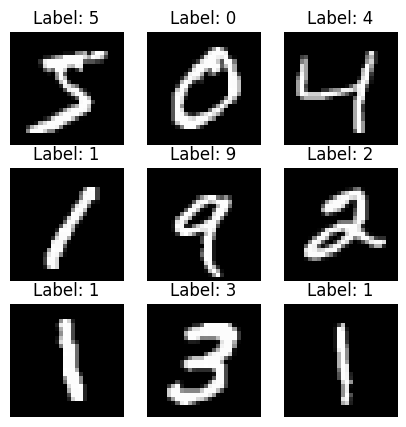

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

# Load data
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Tampilkan contoh
plt.figure(figsize=(5, 5))
for i in range(9):
    plt.subplot(3, 3, i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.show()


###Praktikum D2 Klasifikasi Gambar dengan Model Machine Learning Tradisional

In [2]:
from sklearn import svm
from sklearn.metrics import accuracy_score

x_train_flat = x_train.reshape(len(x_train), -1) / 255.0
x_test_flat = x_test.reshape(len(x_test), -1) / 255.0

clf = svm.SVC(kernel='rbf', gamma='scale')
clf.fit(x_train_flat[:5000], y_train[:5000])

y_pred = clf.predict(x_test_flat)

print("Akurasi (kernel linear):", accuracy_score(y_test, y_pred))

Akurasi (kernel linear): 0.9513


###Praktikum D3 – Membangun CNN Sederhana

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 45s 25ms/step - accuracy: 0.8876 - loss: 0.3739 - val_accuracy: 0.9820 - val_loss: 0.0689
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 49s 29ms/step - accuracy: 0.9809 - loss: 0.0641 - val_accuracy: 0.9832 - val_loss: 0.0632
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 37s 22ms/step - accuracy: 0.9873 - loss: 0.0440 - val_accuracy: 0.9855 - val_loss: 0.0587
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 44s 26ms/step - accuracy: 0.9903 - loss: 0.0295 - val_accuracy: 0.9872 - val_loss: 0.0479
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 38s 22ms/step - accuracy: 0.9937 - loss: 0.0199 - val_accuracy: 0.9877 - val_loss: 0.0477


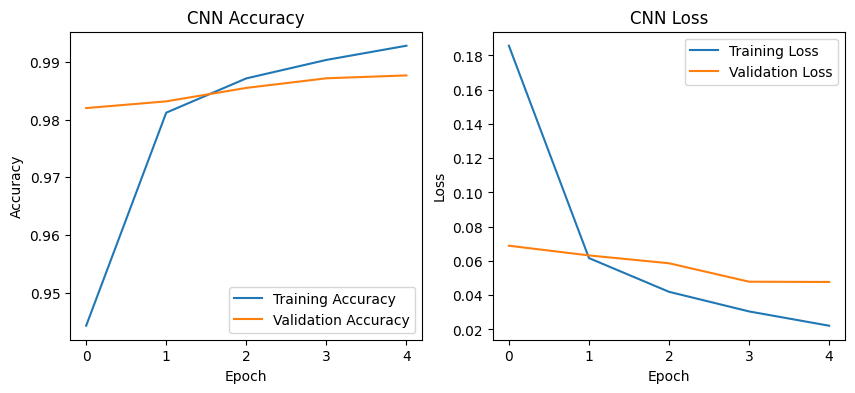

(<MaxPooling2D name=max_pooling2d_1, built=True>,)

In [3]:
import tensorflow as tf
from tensorflow.keras import layers, models

x_train_cnn = x_train.reshape(-1,28,28,1) / 255.0
x_test_cnn = x_test.reshape(-1,28,28,1) / 255.0

model = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(x_train_cnn, y_train, epochs=5, validation_split=0.1)
import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('CNN Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('CNN Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

layers.Conv2D(64, (3,3), activation='relu'),
layers.MaxPooling2D((2,2)),



###Praktikum D4 Eksperimen dengan Dataset Lebih Kompleks (CIFAR-10)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 71s 50ms/step - accuracy: 0.3536 - loss: 1.7613 - val_accuracy: 0.5680 - val_loss: 1.2336
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 69s 49ms/step - accuracy: 0.5783 - loss: 1.1981 - val_accuracy: 0.6216 - val_loss: 1.0917
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 85s 51ms/step - accuracy: 0.6357 - loss: 1.0454 - val_accuracy: 0.6626 - val_loss: 0.9927
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 70s 50ms/step - accuracy: 0.6735 - loss: 0.9422 - val_accuracy: 0.6736 - val_loss: 0.9502
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 70s 50ms/step - accuracy: 0.6937 - loss: 0.8792 - val_accuracy: 0.6614 - val_loss: 0.9746
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 71s 50ms/step - accuracy: 0.7098 - loss: 0.8340 - val_accuracy: 0.6870 - val_loss: 0.9229
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 69s 49ms/step - accuracy: 0.7243 - loss: 0.7938 - val_accuracy: 0.6574 - val_loss: 1.0167
Epoch 8/10
1407/1407 ━━

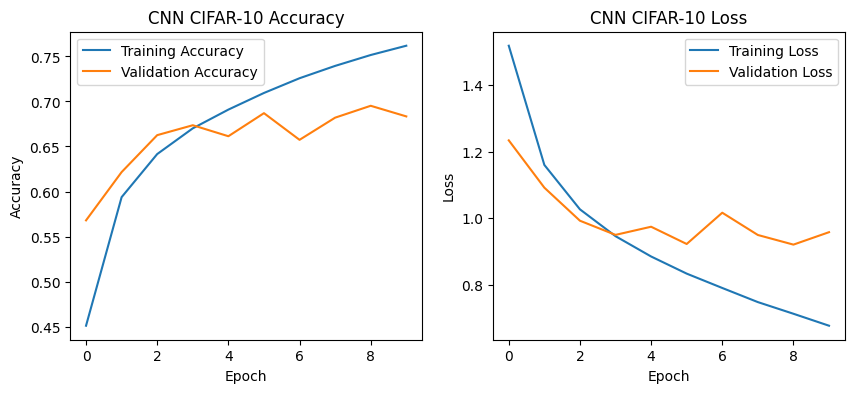

<Dense name=dense_5, built=False>

In [4]:
from tensorflow.keras.datasets import cifar10

(x_train, y_train), (x_test, y_test) = cifar10.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0

model = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(32,32,3)),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(x_train, y_train, epochs=10, validation_split=0.1)
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('CNN CIFAR-10 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('CNN CIFAR-10 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

layers.Dense(64, activation='relu'),
layers.Dropout(0.5),
layers.Dense(10, activation='softmax')



###Praktikum D5 Transfer Learning dengan Model Pra-Latih

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 742s 526ms/step - accuracy: 0.4549 - loss: 1.5622 - val_accuracy: 0.5632 - val_loss: 1.2342
Epoch 2/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 741s 527ms/step - accuracy: 0.5782 - loss: 1.2089 - val_accuracy: 0.5918 - val_loss: 1.1744
Epoch 3/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 725s 515ms/step - accuracy: 0.5980 - loss: 1.1442 - val_accuracy: 0.6028 - val_loss: 1.1547
Epoch 4/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 754s 523ms/step - accuracy: 0.6147 - loss: 1.0967 - val_accuracy: 0.6048 - val_loss: 1.1411
Epoch 5/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 729s 518ms/step - accuracy: 0.6251 - loss: 1.0687 - val_accuracy: 0.6116 - val_loss: 1.1162


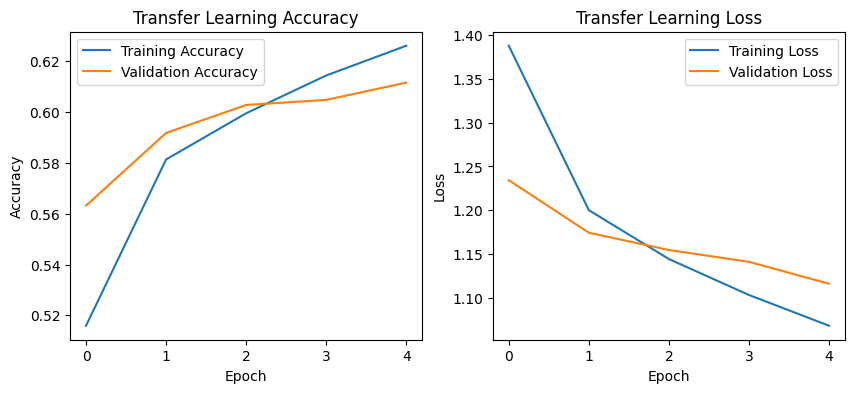

In [5]:
from tensorflow.keras.applications import VGG16

base_model = VGG16(weights='imagenet', include_top=False, input_shape=(32,32,3))
base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(x_train, y_train, epochs=5, validation_split=0.1)
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Transfer Learning Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Transfer Learning Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

base_model.trainable = True
for layer in base_model.layers[:-4]:
    layer.trainable = False


###Praktikum D6 Evaluasi dengan Confusion Matrix dan Metrik Lain

313/313 ━━━━━━━━━━━━━━━━━━━━ 147s 468ms/step
              precision    recall  f1-score   support

           0       0.63      0.70      0.67      1000
           1       0.62      0.70      0.66      1000
           2       0.48      0.53      0.50      1000
           3       0.42      0.48      0.45      1000
           4       0.58      0.48      0.52      1000
           5       0.51      0.51      0.51      1000
           6       0.61      0.67      0.64      1000
           7       0.75      0.55      0.64      1000
           8       0.72      0.73      0.73      1000
           9       0.65      0.56      0.60      1000

    accuracy                           0.59     10000
   macro avg       0.60      0.59      0.59     10000
weighted avg       0.60      0.59      0.59     10000



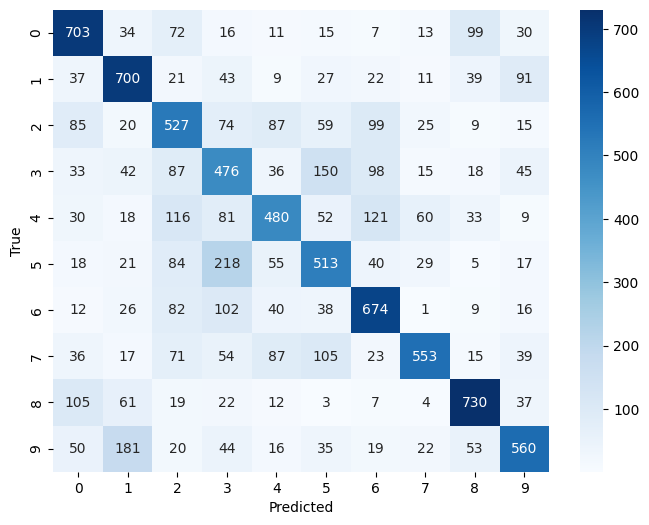

In [6]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
y_pred = model.predict(x_test).argmax(axis=1)
print(classification_report(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()